<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/kornia_visual_uso_practico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 👁️ Kornia: visión por computador con IA, diferenciable y en GPU
**Laboratorio de Códigos**

- 📦 Repositorio: https://github.com/kornia/kornia
- 📚 Documentación: https://kornia.readthedocs.io
- Idea clave: filtros, aumentos, geometría **y modelos de IA** que corren en **GPU** y son **diferenciables**.

> ⚡ Activa la GPU: *Entorno de ejecución → Cambiar tipo de entorno → GPU*.

## 1️⃣ Instalación

In [1]:
!pip install kornia -q
import kornia
print("Kornia versión:", kornia.__version__)

Kornia versión: 0.9.0


## 2️⃣ Configuración

In [2]:
import torch
import kornia as K
import kornia.augmentation as KA
import matplotlib.pyplot as plt
from skimage import data

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cpu


## 3️⃣ Cargar imagen como tensor

/tmp/ipykernel_636/3410802335.py:2: DeprecationWarning: Since kornia 0.8.3 the `image_to_tensor` is deprecated in favor of `kornia.image.image_to_tensor`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  img = K.utils.image_to_tensor(img_np).float() / 255.0      # 3xHxW en [0,1]
/tmp/ipykernel_636/3410802335.py:6: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  plt.figure(figsize=(4,4)); plt.imshow(K.utils.tensor_to_image(img.cpu())); plt.axis("off"); plt.title("Original"); plt.show()


Tensor: torch.Size([1, 3, 512, 512])


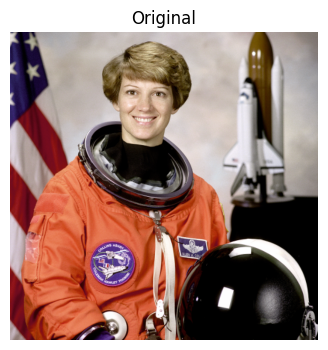

In [3]:
img_np = data.astronaut()                                  # imagen HxWx3 (uint8)
img = K.utils.image_to_tensor(img_np).float() / 255.0      # 3xHxW en [0,1]
img = img.unsqueeze(0).to(device)                          # 1x3xHxW
print("Tensor:", img.shape)

plt.figure(figsize=(4,4))
plt.imshow(K.utils.tensor_to_image(img.cpu()))
plt.axis("off")
plt.title("Original")
plt.show()

## 4️⃣ 🎨 Filtros y bordes en una sola vista

/tmp/ipykernel_636/2490968317.py:12: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  ax.imshow(K.utils.tensor_to_image(t.cpu()), cmap="gray" if t.shape[1] == 1 else None)


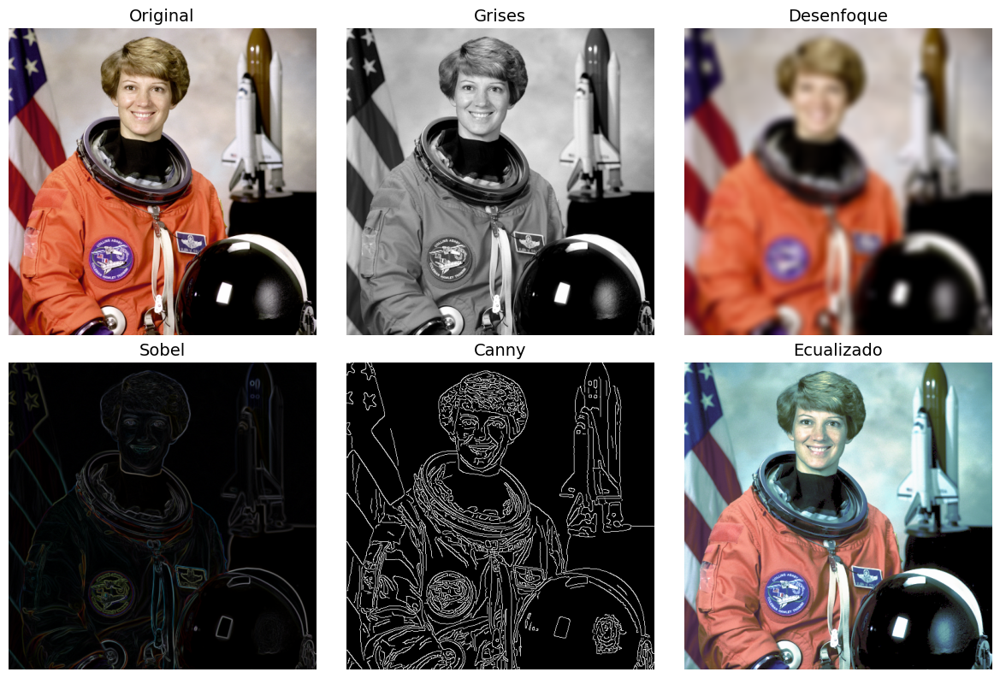

In [4]:
gray   = K.color.rgb_to_grayscale(img)
blur   = K.filters.gaussian_blur2d(img, (21, 21), (6.0, 6.0))
sobel  = K.filters.sobel(img)
_, canny = K.filters.canny(img)
eq     = K.enhance.equalize(img)

panel = [("Original", img), ("Grises", gray), ("Desenfoque", blur),
         ("Sobel", sobel), ("Canny", canny), ("Ecualizado", eq)]

fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for ax, (title, t) in zip(axs.ravel(), panel):
    ax.imshow(K.utils.tensor_to_image(t.cpu()),
              cmap="gray" if t.shape[1] == 1 else None)
    ax.set_title(title, fontsize=14); ax.axis("off")
plt.tight_layout(); plt.show()

## 5️⃣ Modificación de datos (8 variaciones al instante)

/tmp/ipykernel_636/2148824727.py:14: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  ax.imshow(K.utils.tensor_to_image(t.cpu())); ax.axis("off")


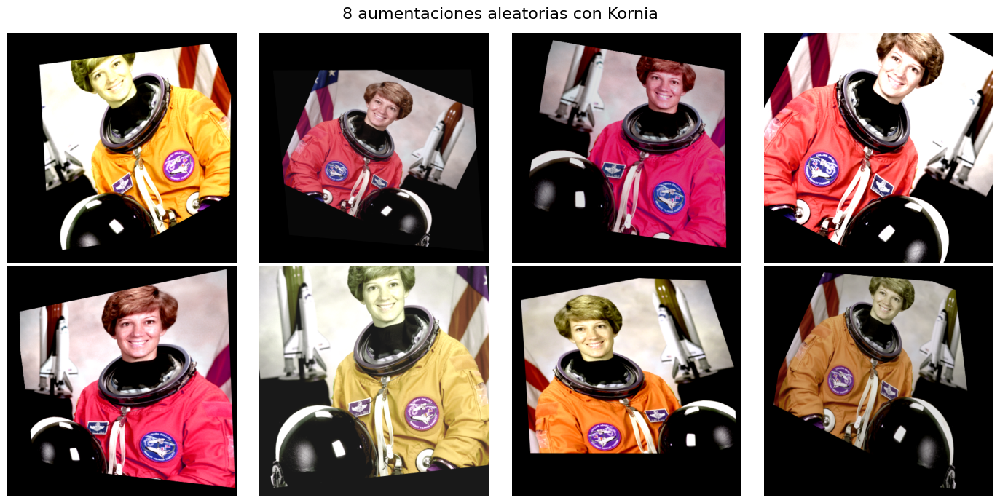

In [5]:
aug = KA.AugmentationSequential(
    KA.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.8, 1.2), p=1.0),
    KA.ColorJitter(0.4, 0.4, 0.4, 0.1, p=1.0),
    KA.RandomPerspective(0.4, p=0.7),
    KA.RandomHorizontalFlip(p=0.5),
    data_keys=["input"],
).to(device)

batch = img.repeat(8, 1, 1, 1)
out = aug(batch)

fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, t in zip(axs.ravel(), out):
    ax.imshow(K.utils.tensor_to_image(t.cpu())); ax.axis("off")
plt.suptitle("8 aumentaciones aleatorias con Kornia", fontsize=16)
plt.tight_layout(); plt.show()

## 6️⃣ 🔥 Geometría DIFERENCIABLE: Kornia aprende el ángulo con backpropagation

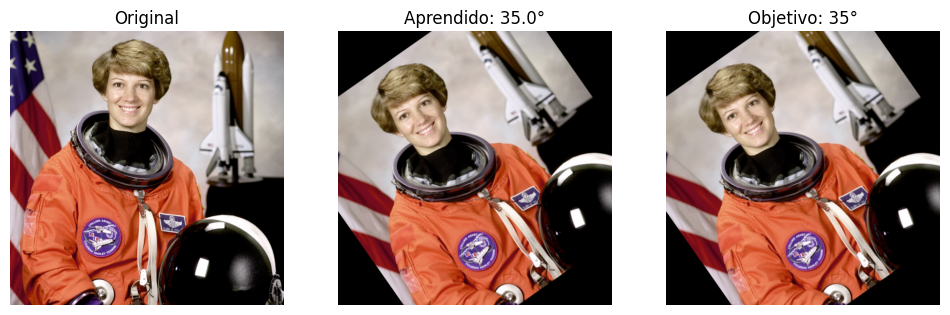

🎯 Ángulo encontrado: 35.00° (real: 35°)


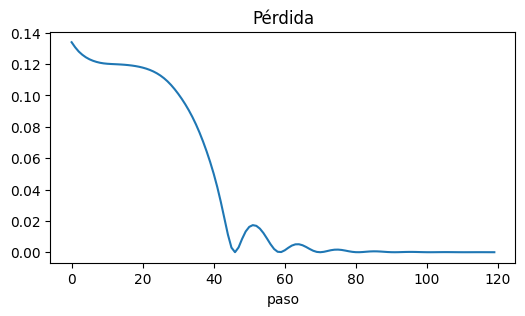

In [6]:
from IPython.display import clear_output

target = K.geometry.transform.rotate(img, torch.tensor([35.0], device=device))
angle = torch.nn.Parameter(torch.tensor([0.0], device=device))
opt = torch.optim.Adam([angle], lr=0.8)

def smooth(x): return K.filters.gaussian_blur2d(x, (15, 15), (4.0, 4.0))
target_s = smooth(target)

history = []
for step in range(120):
    opt.zero_grad()
    pred = K.geometry.transform.rotate(img, angle)
    loss = torch.nn.functional.mse_loss(smooth(pred), target_s)
    loss.backward(); opt.step()
    history.append((angle.item(), loss.item()))

    if step % 20 == 0 or step == 119:
        clear_output(wait=True)
        fig, axs = plt.subplots(1, 3, figsize=(12, 4))
        axs[0].imshow(K.utils.tensor_to_image(img.cpu())); axs[0].set_title("Original")
        axs[1].imshow(K.utils.tensor_to_image(pred.detach().cpu()))
        axs[1].set_title(f"Aprendido: {angle.item():.1f}°")
        axs[2].imshow(K.utils.tensor_to_image(target.cpu())); axs[2].set_title("Objetivo: 35°")
        for a in axs: a.axis("off")
        plt.show()

print(f"🎯 Ángulo encontrado: {angle.item():.2f}° (real: 35°)")
plt.figure(figsize=(6,3)); plt.plot([h[1] for h in history])
plt.title("Pérdida")
plt.xlabel("paso")
plt.show()

---
# BLOQUE IA: modelos preentrenados dentro de Kornia
Los pesos se descargan solos la primera vez (necesitas internet en Colab).

## 7️⃣ LoFTR: emparejar dos vistas sin detectores clásicos + homografía con RANSAC

Downloading: "https://huggingface.co/kornia/loftr/resolve/main/loftr_outdoor.ckpt" to /root/.cache/torch/hub/checkpoints/loftr_outdoor.ckpt
100%|██████████| 44.2M/44.2M [00:00<00:00, 74.6MB/s]


Correspondencias con confianza > 0.8: 1390
Inliers RANSAC: 1390 de 1390


/tmp/ipykernel_636/377156724.py:31: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  a = K.utils.tensor_to_image(base.cpu()); b = K.utils.tensor_to_image(view2.cpu())


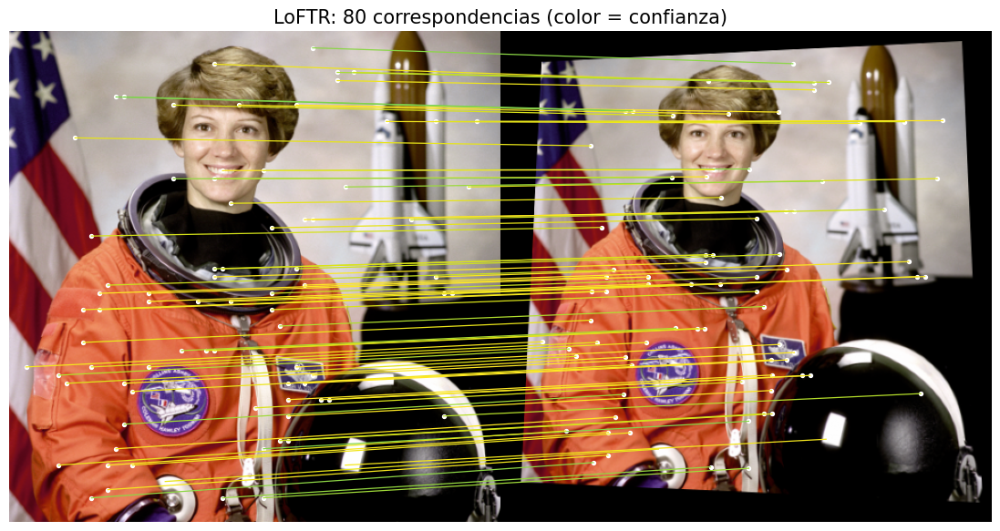

/tmp/ipykernel_636/377156724.py:46: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  ax.imshow(K.utils.tensor_to_image(t.cpu())); ax.set_title(title); ax.axis("off")


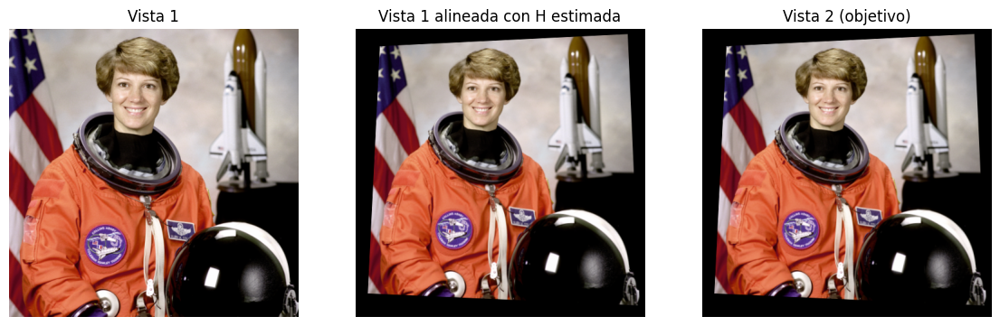

In [7]:
from kornia.feature import LoFTR
from kornia.geometry.ransac import RANSAC

S = 480
base = K.geometry.transform.resize(img, (S, S))
g0 = K.color.rgb_to_grayscale(base)

# Segunda vista: la misma imagen deformada con una homografía CONOCIDA
src = torch.tensor([[[0, 0], [S-1, 0], [S-1, S-1], [0, S-1]]], dtype=torch.float32, device=device)
dst = torch.tensor([[[40, 30], [450, 10], [470, 460], [20, 440]]], dtype=torch.float32, device=device)
M = K.geometry.transform.get_perspective_transform(src, dst)
view2 = K.geometry.transform.warp_perspective(base, M, (S, S))
g1 = K.color.rgb_to_grayscale(view2)

matcher = LoFTR(pretrained="outdoor").to(device).eval()
with torch.inference_mode():
    out = matcher({"image0": g0, "image1": g1})

k0, k1, conf = out["keypoints0"], out["keypoints1"], out["confidence"]
keep = conf > 0.8
k0, k1, conf = k0[keep], k1[keep], conf[keep]
print(f"Correspondencias con confianza > 0.8: {len(k0)}")

# Estimar la homografía con RANSAC en la CPU para evitar incompatibilidades de kernel de CUDA
ransac = RANSAC("homography", inl_th=3.0)
H_est, inliers = ransac(k0.cpu(), k1.cpu())
H_est, inliers = H_est.to(device), inliers.to(device)
print(f"Inliers RANSAC: {int(inliers.sum())} de {len(k0)}")

# Dibujar emparejamientos
a = K.utils.tensor_to_image(base.cpu()); b = K.utils.tensor_to_image(view2.cpu())
canvas = torch.cat([torch.from_numpy(a), torch.from_numpy(b)], dim=1).numpy()
plt.figure(figsize=(14, 7)); plt.imshow(canvas)
idx = torch.randperm(len(k0))[:80]
p0, p1, cc = k0[idx].cpu(), k1[idx].cpu(), conf[idx].cpu()
for (x0, y0), (x1, y1), c in zip(p0, p1, cc):
    plt.plot([x0, x1 + S], [y0, y1], color=plt.cm.viridis(float(c)), lw=0.9)
    plt.scatter([x0, x1 + S], [y0, y1], s=8, color="white")
plt.axis("off"); plt.title("LoFTR: 80 correspondencias (color = confianza)", fontsize=15); plt.show()

# Alinear la primera vista con la segunda usando la homografía estimada
aligned = K.geometry.transform.warp_perspective(base, H_est[None], (S, S))
diff = (aligned - view2).abs().mean(1, keepdim=True)
fig, axs = plt.subplots(1, 3, figsize=(14, 5))
for ax, (t, title) in zip(axs, [(base, "Vista 1"), (aligned, "Vista 1 alineada con H estimada"), (view2, "Vista 2 (objetivo)")]):
    ax.imshow(K.utils.tensor_to_image(t.cpu())); ax.set_title(title); ax.axis("off")
plt.show()

## 8️⃣ Detección de caras con YuNet (modelo de IA incluido en Kornia)

Downloading: "https://huggingface.co/kornia/yunet/resolve/main/yunet_final.pth" to /root/.cache/torch/hub/checkpoints/yunet_final.pth
100%|██████████| 396k/396k [00:00<00:00, 1.87MB/s]
/tmp/ipykernel_636/2753766047.py:8: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`. The `kornia.utils` module is deprecated. Import from `kornia.image` instead.
  ax.imshow(K.utils.tensor_to_image(img.cpu())); ax.axis("off")


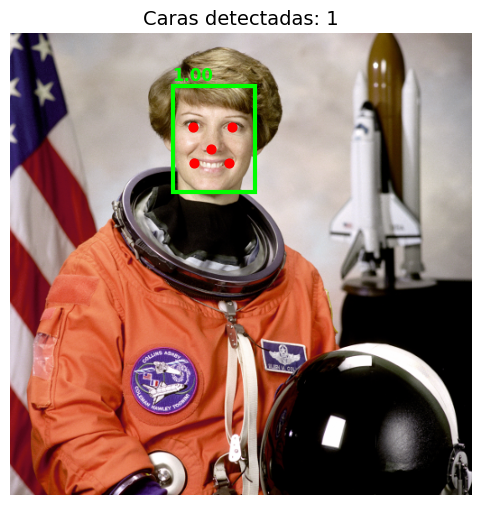

In [8]:
import matplotlib.patches as patches

face_det = K.contrib.FaceDetector().to(device)
with torch.no_grad():
    dets = face_det(img * 255.0)          # el detector espera valores 0-255

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(K.utils.tensor_to_image(img.cpu())); ax.axis("off")
n = 0
for d in dets[0].cpu():
    score = float(d[14])
    if score < 0.6:
        continue
    x1, y1, x2, y2 = [float(v) for v in d[:4]]
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   edgecolor="lime", linewidth=3))
    kps = d[4:14].view(5, 2)              # ojos, nariz y boca
    ax.scatter(kps[:, 0], kps[:, 1], s=40, c="red")
    ax.text(x1, y1 - 6, f"{score:.2f}", color="lime", fontsize=12, weight="bold")
    n += 1
ax.set_title(f"Caras detectadas: {n}", fontsize=14); plt.show()

## 9️⃣ Detección de bordes con IA (DexiNed) vs Canny clásico

Dispositivo: cpu


Downloading: "https://huggingface.co/kornia/dexined/resolve/main/DexiNed_BIPED_10.pth" to /root/.cache/torch/hub/checkpoints/DexiNed_BIPED_10.pth
100%|██████████| 135M/135M [00:01<00:00, 86.4MB/s]


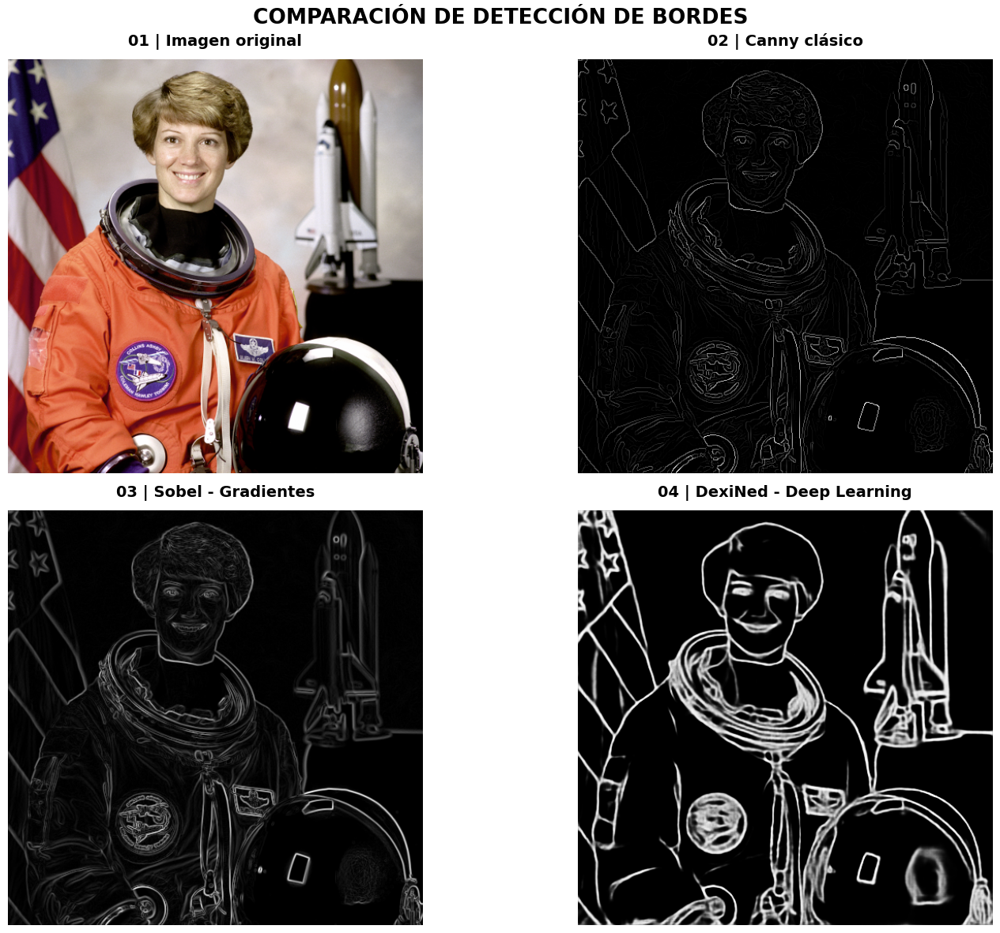

In [9]:
import torch
import kornia as K
import matplotlib.pyplot as plt
import numpy as np

from kornia.contrib.edge_detection import EdgeDetectorBuilder

# ============================================
# 1. CONFIGURACIÓN
# ============================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

# img debe tener formato [B, 3, H, W]
# Valores RGB normalizados entre 0 y 1

img = img.float().to(device)

if img.max() > 1:
    img = img / 255.0

# ============================================
# 2. CANNY CLÁSICO
# ============================================

with torch.no_grad():
    canny_edges, canny_threshold = K.filters.canny(
        img,
        low_threshold=0.1,
        high_threshold=0.2
    )

# ============================================
# 3. SOBEL - GRADIENTES
# ============================================

with torch.no_grad():

    sobel = K.filters.spatial_gradient(
        K.color.rgb_to_grayscale(img),
        mode="sobel",
        order=1
    )

    gx = sobel[:, :, 0]
    gy = sobel[:, :, 1]

    sobel_edges = torch.sqrt(gx**2 + gy**2)

    sobel_edges = sobel_edges / (
        sobel_edges.amax(dim=(-2, -1), keepdim=True) + 1e-8
    )

# ============================================
# 4. DEXINED - INTELIGENCIA ARTIFICIAL
# ============================================

dexined = EdgeDetectorBuilder.build(
    model_name="dexined",
    pretrained=True,
    image_size=512
).to(device)

dexined.eval()

with torch.inference_mode():
    dexined_output = dexined(img)

# La API actual devuelve una lista de mapas
dexined_edges = dexined_output[0]

# ============================================
# 5. CONVERTIR PARA VISUALIZACIÓN
# ============================================

def to_numpy(tensor):

    tensor = tensor.detach().cpu()

    if tensor.ndim == 4:
        tensor = tensor[0]

    if tensor.shape[0] == 1:
        return tensor.squeeze(0).numpy()

    return tensor.permute(1, 2, 0).numpy()


original = to_numpy(img)
canny = to_numpy(canny_edges)
sobel = to_numpy(sobel_edges)
dexined = to_numpy(dexined_edges)

# ============================================
# 6. VISUALIZACIÓN COMPARATIVA
# ============================================

fig, axs = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

axs = axs.flatten()

images = [
    original,
    canny,
    sobel,
    dexined
]

titles = [
    "01 | Imagen original",
    "02 | Canny clásico",
    "03 | Sobel - Gradientes",
    "04 | DexiNed - Deep Learning"
]

cmaps = [
    None,
    "gray",
    "gray",
    "gray"
]

for ax, image, title, cmap in zip(
    axs, images, titles, cmaps
):

    ax.imshow(image, cmap=cmap)

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.axis("off")

plt.suptitle(
    "COMPARACIÓN DE DETECCIÓN DE BORDES",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

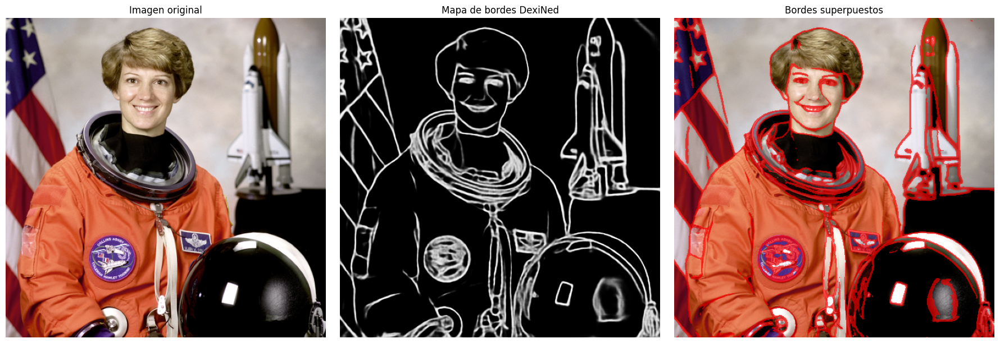

In [10]:
# Convertir mapa de bordes a RGB
edge_rgb = np.repeat(
    dexined[..., None],
    3,
    axis=2
)

# Crear superposición
overlay = original.copy()

# Bordes en color rojo
mask = dexined > 0.35

overlay[mask] = (
    0.35 * overlay[mask] +
    0.65 * np.array([1.0, 0.0, 0.0])
)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].imshow(original)
axs[0].set_title("Imagen original")

axs[1].imshow(dexined, cmap="gray")
axs[1].set_title("Mapa de bordes DexiNed")

axs[2].imshow(overlay)
axs[2].set_title("Bordes superpuestos")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

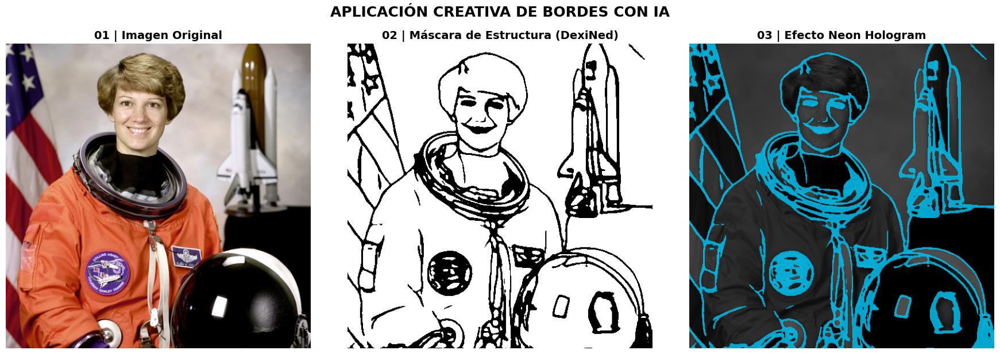

In [11]:
# ===================================================================
# NUEVO EJEMPLO: Efecto de Neón Holográfico sobre el Astronauta
# ===================================================================
import numpy as np
import matplotlib.pyplot as plt

# 1. Crear una base dramática: convertimos la imagen original a escala de grises y la oscurecemos
gray_dim = np.mean(original, axis=2, keepdims=True) * 0.3
gray_dim_rgb = np.repeat(gray_dim, 3, axis=2)

# 2. Definir una máscara de bordes de DexiNed con un umbral suave para capturar detalles finos
neon_mask = dexined > 0.2

# 3. Crear el canal del efecto Neón (color Cian/Celeste: R=0.0, G=0.9, B=1.0)
neon_color = np.array([0.0, 0.8, 1.0])

# 4. Combinar: donde hay bordes proyectamos el neón brillante, en el resto la imagen atenuada
hologram = gray_dim_rgb.copy()
hologram[neon_mask] = (
    0.2 * hologram[neon_mask] +
    0.8 * neon_color
)

# 5. Graficar los resultados de forma comparativa
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Vista 1: Original
axs[0].imshow(original)
axs[0].set_title("01 | Imagen Original", fontsize=14, fontweight="bold")
axs[0].axis("off")

# Vista 2: Solo los bordes de la IA (estilo plano técnico)
axs[1].imshow(1.0 - (dexined > 0.2), cmap="gray")
axs[1].set_title("02 | Máscara de Estructura (DexiNed)", fontsize=14, fontweight="bold")
axs[1].axis("off")

# Vista 3: Efecto Holograma
axs[2].imshow(hologram)
axs[2].set_title("03 | Efecto Neon Hologram", fontsize=14, fontweight="bold")
axs[2].axis("off")

plt.suptitle("APLICACIÓN CREATIVA DE BORDES CON IA", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 🔟 Entrenar una red con imágenes modificadas

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 395kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.73MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]


SIN aumentos | época 1 | acc test: 96.65%
SIN aumentos | época 2 | acc test: 97.82%
SIN aumentos | época 3 | acc test: 98.18%
CON aumentos | época 1 | acc test: 97.39%
CON aumentos | época 2 | acc test: 97.81%
CON aumentos | época 3 | acc test: 98.38%


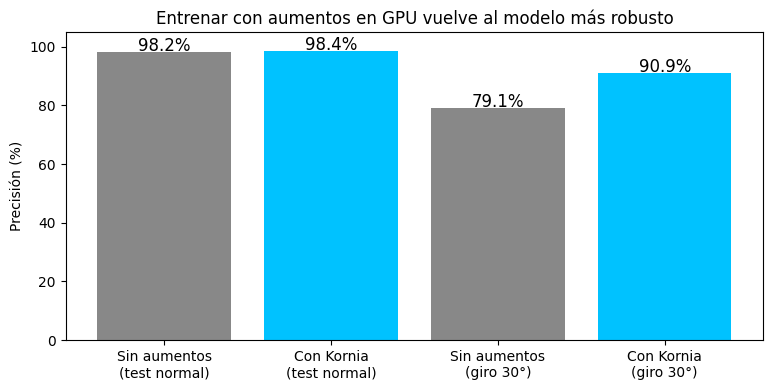

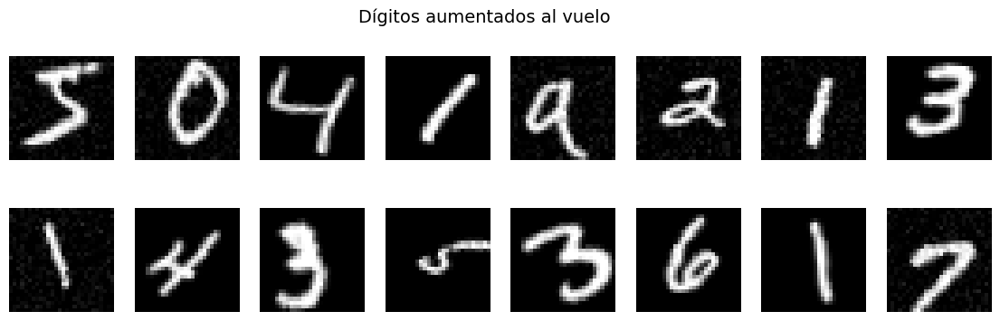

In [22]:
import torch.nn as nn, torch.nn.functional as F, torchvision

tr = torchvision.datasets.MNIST("/content/data", train=True, download=True)
te = torchvision.datasets.MNIST("/content/data", train=False, download=True)
Xtr = tr.data.unsqueeze(1).float().div(255).to(device); ytr = tr.targets.to(device)
Xte = te.data.unsqueeze(1).float().div(255).to(device); yte = te.targets.to(device)

train_aug = KA.AugmentationSequential(
    KA.RandomAffine(degrees=25, translate=(0.1, 0.1), scale=(0.85, 1.15), p=1.0),
    KA.RandomGaussianNoise(std=0.05, p=0.5),
    data_keys=["input"],
).to(device)

def make_model():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 5 * 5, 10),
    ).to(device)

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return (model(X).argmax(1) == y).float().mean().item() * 100

def train(use_aug, epochs=3, bs=256):
    model = make_model(); opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            xb, yb = Xtr[idx], ytr[idx]
            if use_aug:
                xb = train_aug(xb).clamp(0, 1)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        print(f"{'CON' if use_aug else 'SIN'} aumentos | época {ep+1} | acc test: {accuracy(model, Xte, yte):.2f}%")
    return model

m_plain = train(False)
m_aug = train(True)

# Prueba difícil: dígitos de test girados 30°
Xrot = K.geometry.transform.rotate(Xte, torch.full((len(Xte),), 30.0, device=device))
res = {
    "Sin aumentos\n(test normal)": accuracy(m_plain, Xte, yte),
    "Con Kornia\n(test normal)": accuracy(m_aug, Xte, yte),
    "Sin aumentos\n(giro 30°)": accuracy(m_plain, Xrot, yte),
    "Con Kornia\n(giro 30°)": accuracy(m_aug, Xrot, yte),
}
plt.figure(figsize=(9, 4))
bars = plt.bar(res.keys(), res.values(), color=["#888", "#00c2ff", "#888", "#00c2ff"])
for b, v in zip(bars, res.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=12)
plt.ylim(0, 105); plt.ylabel("Precisión (%)"); plt.title("Entrenar con aumentos en GPU vuelve al modelo más robusto")
plt.show()

# Ejemplos de dígitos aumentados
sample = train_aug(Xtr[:16]).clamp(0, 1).cpu()
fig, axs = plt.subplots(2, 8, figsize=(14, 4))
for ax, t in zip(axs.ravel(), sample):
    ax.imshow(t[0], cmap="gray"); ax.axis("off")
plt.suptitle("Dígitos aumentados al vuelo", fontsize=14); plt.show()

## Siguientes pasos
`kornia.feature` (DISK, LightGlue), `kornia.contrib.ImageStitcher`, `kornia.contrib.VisualPrompter` (SAM) y `kornia.geometry`.

**Laboratorio de Códigos**